# CNN: a 1D convolutional neural network

A CNN slides small filters along its input to find local patterns. It is designed for images and sequences, where neighbouring values are related. Here the 45 features are treated as a 1D signal, and the filters look at 3 neighbouring features at a time.

**Feasibility, and an honest caveat:** it runs fine, and many intrusion-detection papers do this. But the **order of your features is arbitrary** (nothing makes `sbytes` a "neighbour" of `dbytes`), so the convolutions have no natural meaning here. Present it as a comparison model, not as a better fit for the data, and don't be surprised if it does not beat the plain MLP.

Run after the preprocessing notebook. Everything is evaluated on the validation set.

## 1. Imports

In [1]:
# %pip install tensorflow matplotlib     # uncomment once if missing

import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
import keras
from keras import layers

print("keras", keras.__version__)

keras 3.15.1


## 2. Config

In [2]:
PROCESSED_DIR = "processed"
MODEL_DIR = "models"
SEED = 42

LEARNING_RATE = 1e-3
BATCH_SIZE = 512
EPOCHS = 60              # early stopping usually ends training much sooner
PATIENCE = 8

CONV_FILTERS = (32, 64)   # one Conv1D block per value
KERNEL_SIZE = 3
DENSE_UNITS = 64
DROPOUT = 0.3

## 3. Load the processed data

In [3]:
proc = Path(PROCESSED_DIR)
data = np.load(proc / "unsw_nb15_processed.npz")
meta = json.loads((proc / "meta.json").read_text())

X_train, X_val = data["X_train"].astype("float32"), data["X_val"].astype("float32")
yb_train, yb_val = data["y_bin_train"].astype(int), data["y_bin_val"].astype(int)
ym_train, ym_val = data["y_multi_train"].astype(int), data["y_multi_val"].astype(int)
feature_names = meta["feature_names"]
class_names = meta["class_names"]
n_features, n_classes = X_train.shape[1], len(class_names)

cw_bin = {int(k): v for k, v in meta["class_weight_binary"].items()}
cw_multi = {int(k): v for k, v in meta["class_weight_multi"].items()}

print("X_train:", X_train.shape, "  X_val:", X_val.shape)
print("classes:", class_names)

X_train: (140272, 39)   X_val: (35069, 39)
classes: ['Normal', 'DoS', 'Reconnaissance', 'Fuzzers', 'Exploits', 'Generic', 'Other']


## 4. Helpers (same evaluation as every other notebook)

In [4]:
def ms_per_1000(predict_fn, X, n=5000):
    """Prediction time in milliseconds per 1,000 flows (a model that is too slow cannot run live)."""
    Xs = X[:n]
    t0 = time.perf_counter()
    predict_fn(Xs)
    return round(1e6 * (time.perf_counter() - t0) / len(Xs), 1)


def report_binary(y_true, pred, title, score=None, ms=None):
    print(classification_report(y_true, pred, target_names=["Normal", "Attack"], digits=4))
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    fpr = fp / max(fp + tn, 1)
    if score is not None:
        print(f"ROC-AUC:              {roc_auc_score(y_true, score):.4f}")
    print(f"False positive rate:  {fpr:.4f}  ({fp} normal flows flagged as attacks)")
    print(f"False negative rate:  {fn / max(fn + tp, 1):.4f}  ({fn} attacks missed)")
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, display_labels=["Normal", "Attack"], cmap="Blues", ax=ax, values_format="d")
    ax.set_title(f"{title}: validation confusion matrix")
    plt.tight_layout()
    plt.show()
    return {"model": title,
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred),
            "false_pos_rate": fpr,
            "ms_per_1000_flows": ms}


def report_multiclass(y_true, pred, title, ms=None):
    labels = list(range(n_classes))
    print(classification_report(y_true, pred, labels=labels, target_names=class_names,
                                digits=4, zero_division=0))
    print("macro F1:    %.4f" % f1_score(y_true, pred, average="macro"))
    print("weighted F1: %.4f" % f1_score(y_true, pred, average="weighted"))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        cmap="Blues", ax=axes[0], values_format="d", xticks_rotation=45)
    axes[0].set_title("Counts")
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        normalize="true", cmap="Blues", ax=axes[1], values_format=".2f", xticks_rotation=45)
    axes[1].set_title("Row-normalised (share of each true class)")
    plt.suptitle(f"{title}: validation confusion matrices")
    plt.tight_layout()
    plt.show()
    flagged = np.asarray(pred) != 0          # class 0 is Normal
    rows = []
    for i, name in enumerate(class_names):
        m = np.asarray(y_true) == i
        rows.append({"true class": name, "flows": int(m.sum()),
                     "flagged as attack (%)": round(100 * flagged[m].mean(), 2),
                     "correct type (%)": round(100 * (np.asarray(pred)[m] == i).mean(), 2)})
    display(pd.DataFrame(rows))
    return {"model": title + " (macro)",
            "precision": precision_score(y_true, pred, average="macro", zero_division=0),
            "recall": recall_score(y_true, pred, average="macro", zero_division=0),
            "f1": f1_score(y_true, pred, average="macro"),
            "false_pos_rate": np.nan,
            "ms_per_1000_flows": ms}

In [5]:
keras.utils.set_random_seed(SEED)


def head(x, n_out, binary):
    if binary:
        return layers.Dense(1, activation="sigmoid")(x)
    return layers.Dense(n_out, activation="softmax")(x)


def compile_model(model, binary):
    if binary:
        loss, metrics = "binary_crossentropy", [keras.metrics.AUC(name="auc")]
    else:
        loss, metrics = "sparse_categorical_crossentropy", ["accuracy"]
    model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss=loss, metrics=metrics)
    return model


def fit_model(model, X_tr, y_tr, X_va, y_va, class_weight):
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
    ]
    t0 = time.time()
    hist = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=EPOCHS,
                     batch_size=BATCH_SIZE, class_weight=class_weight,
                     callbacks=callbacks, verbose=2)
    print(f"trained {len(hist.history['loss'])} epochs in {time.time() - t0:.1f}s")
    return hist


def plot_history(hist, metric, title):
    h = hist.history
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(h["loss"], label="train")
    axes[0].plot(h["val_loss"], label="validation")
    axes[0].set_title("Loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(h[metric], label="train")
    axes[1].plot(h["val_" + metric], label="validation")
    axes[1].set_title(metric.upper()); axes[1].set_xlabel("epoch"); axes[1].legend()
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

## 5. Architecture

The 45 features are reshaped to a sequence of length 45 with 1 channel. Each block is Conv1D, BatchNorm, ReLU, MaxPool. The result is flattened and passed through a Dense layer to the output.

In [6]:
def build_model(n_in, n_out, binary):
    inputs = keras.Input(shape=(n_in,))
    x = layers.Reshape((n_in, 1))(inputs)
    for filters in CONV_FILTERS:
        x = layers.Conv1D(filters, KERNEL_SIZE, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.MaxPooling1D(pool_size=2, padding="same")(x)
    x = layers.Flatten()(x)
    x = layers.Dense(DENSE_UNITS, activation="relu")(x)
    x = layers.Dropout(DROPOUT)(x)
    return keras.Model(inputs, head(x, n_out, binary))

## 6. Binary model (normal vs attack)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 39)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 39, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 39, 32)         │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 39, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 39, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 20, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 20, 64)         │         6,144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 20, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 20, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 10, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 640)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        41,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 47,713 (186.38 KB)

 Trainable params: 47,521 (185.63 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/60
274/274 - 5s - 18ms/step - auc: 0.9728 - loss: 0.2086 - val_auc: 0.9809 - val_loss: 0.3045 - learning_rate: 0.0010
Epoch 2/60
274/274 - 4s - 13ms/step - auc: 0.9840 - loss: 0.1582 - val_auc: 0.9897 - val_loss: 0.1424 - learning_rate: 0.0010
Epoch 3/60
274/274 - 3s - 11ms/step - auc: 0.9857 - loss: 0.1489 - val_auc: 0.9903 - val_loss: 0.1362 - learning_rate: 0.0010
Epoch 4/60
274/274 - 6s - 21ms/step - auc: 0.9864 - loss: 0.1445 - val_auc: 0.9905 - val_loss: 0.1417 - learning_rate: 0.0010
Epoch 5/60
274/274 - 3s - 13ms/step - auc: 0.9869 - loss: 0.1418 - val_auc: 0.9907 - val_loss: 0.1246 - learning_rate: 0.0010
Epoch 6/60
274/274 - 4s - 13ms/step - auc: 0.9874 - loss: 0.1389 - val_auc: 0.9907 - val_loss: 0.1391 - learning_rate: 0.0010
Epoch 7/60
274/274 - 4s - 13ms/step - auc: 0.9876 - loss: 0.1376 - val_auc: 0.9911 - val_loss: 0.1152 - learning_rate: 0.0010
Epoch 8/60
274/274 - 3s - 12ms/step - auc: 0.9879 - loss: 0.1361 - val_auc: 0.9911 - val_loss: 0.1278 - learning_rate:

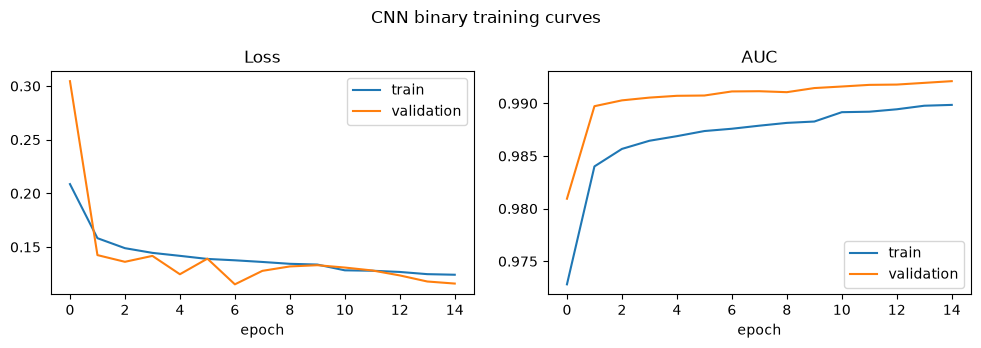

In [7]:
model_bin = compile_model(build_model(n_features, 1, True), True)
model_bin.summary()
hist_bin = fit_model(model_bin, X_train, yb_train, X_val, yb_val, cw_bin)
plot_history(hist_bin, "auc", "CNN binary training curves")

              precision    recall  f1-score   support

      Normal     0.8820    0.9501    0.9148     11200
      Attack     0.9757    0.9403    0.9577     23869

    accuracy                         0.9435     35069
   macro avg     0.9288    0.9452    0.9362     35069
weighted avg     0.9458    0.9435    0.9440     35069

ROC-AUC:              0.9913
False positive rate:  0.0499  (559 normal flows flagged as attacks)
False negative rate:  0.0597  (1424 attacks missed)


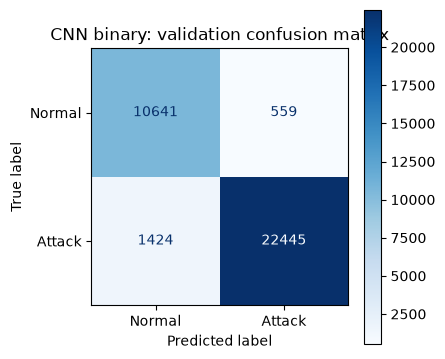

In [8]:
proba_bin = model_bin.predict(X_val, batch_size=4096, verbose=0).ravel()
pred_bin = (proba_bin >= 0.5).astype(int)
row_bin = report_binary(
    yb_val, pred_bin, "CNN binary", score=proba_bin,
    ms=ms_per_1000(lambda X: model_bin.predict(X, batch_size=4096, verbose=0), X_val))

## 7. Multiclass model

Epoch 1/60
274/274 - 5s - 17ms/step - accuracy: 0.6888 - loss: 1.0247 - val_accuracy: 0.6627 - val_loss: 0.8777 - learning_rate: 0.0010
Epoch 2/60
274/274 - 4s - 13ms/step - accuracy: 0.7394 - loss: 0.8516 - val_accuracy: 0.7646 - val_loss: 0.5994 - learning_rate: 0.0010
Epoch 3/60
274/274 - 4s - 14ms/step - accuracy: 0.7480 - loss: 0.8094 - val_accuracy: 0.7791 - val_loss: 0.5653 - learning_rate: 0.0010
Epoch 4/60
274/274 - 4s - 13ms/step - accuracy: 0.7508 - loss: 0.7879 - val_accuracy: 0.7774 - val_loss: 0.5600 - learning_rate: 0.0010
Epoch 5/60
274/274 - 4s - 13ms/step - accuracy: 0.7562 - loss: 0.7702 - val_accuracy: 0.7802 - val_loss: 0.5443 - learning_rate: 0.0010
Epoch 6/60
274/274 - 4s - 14ms/step - accuracy: 0.7564 - loss: 0.7623 - val_accuracy: 0.7807 - val_loss: 0.5426 - learning_rate: 0.0010
Epoch 7/60
274/274 - 4s - 14ms/step - accuracy: 0.7583 - loss: 0.7504 - val_accuracy: 0.7787 - val_loss: 0.5343 - learning_rate: 0.0010
Epoch 8/60
274/274 - 3s - 12ms/step - accuracy: 

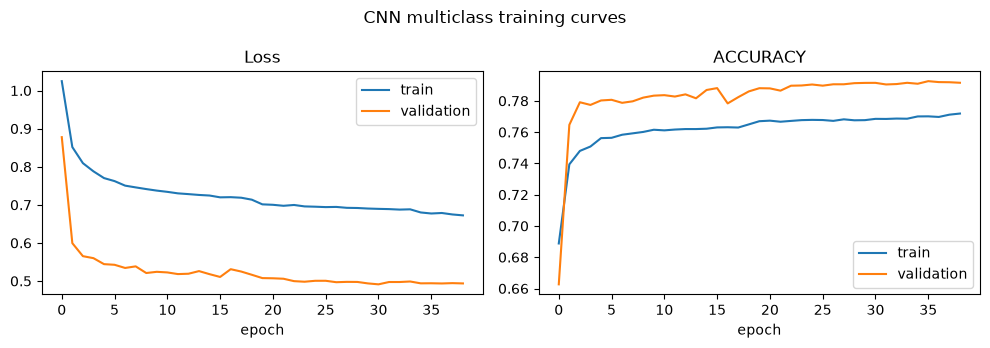

In [9]:
model_multi = compile_model(build_model(n_features, n_classes, False), False)
hist_multi = fit_model(model_multi, X_train, ym_train, X_val, ym_val, cw_multi)
plot_history(hist_multi, "accuracy", "CNN multiclass training curves")

                precision    recall  f1-score   support

        Normal     0.9952    0.8494    0.9165     11200
           DoS     0.3315    0.8096    0.4704      2453
Reconnaissance     0.8191    0.7980    0.8084      2099
       Fuzzers     0.6461    0.8655    0.7399      3637
      Exploits     0.8542    0.4859    0.6195      6678
       Generic     0.9983    0.9804    0.9893      8000
         Other     0.3664    0.3463    0.3561      1002

      accuracy                         0.7915     35069
     macro avg     0.7158    0.7336    0.7000     35069
  weighted avg     0.8579    0.7915    0.8045     35069

macro F1:    0.7000
weighted F1: 0.8045


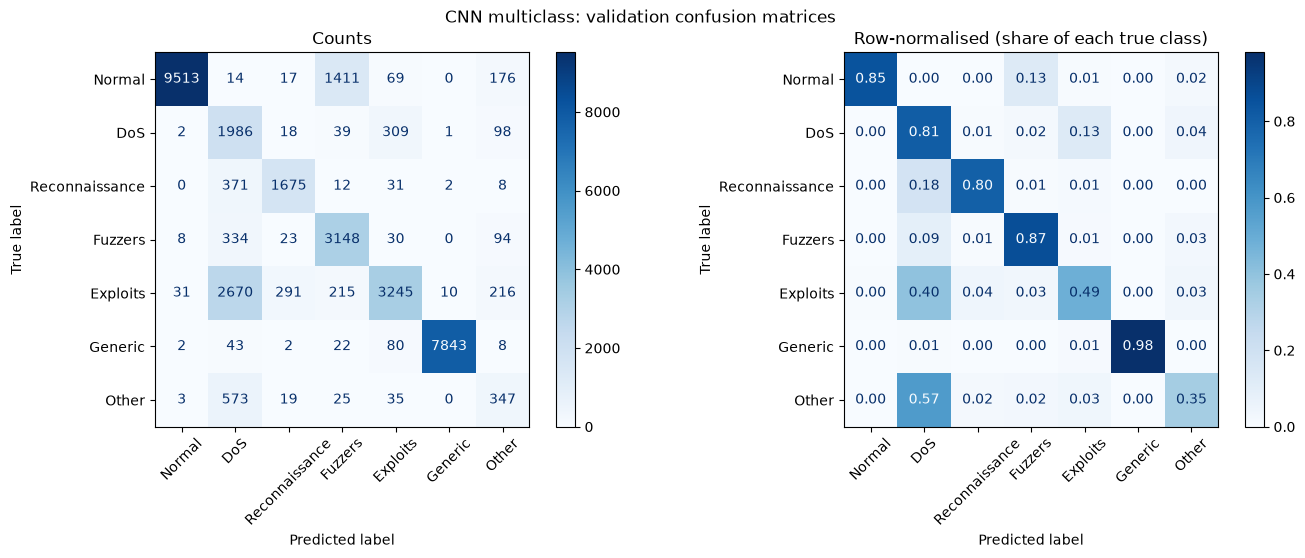

,true class,flows,flagged as attack (%),correct type (%)
0,Normal,11200,15.06,84.94
1,DoS,2453,99.92,80.96
2,Reconnaissance,2099,100.00,79.80
3,Fuzzers,3637,99.78,86.55
4,Exploits,6678,99.54,48.59
5,Generic,8000,99.98,98.04
6,Other,1002,99.70,34.63


In [10]:
pred_multi = model_multi.predict(X_val, batch_size=4096, verbose=0).argmax(axis=1)
row_multi = report_multiclass(
    ym_val, pred_multi, "CNN multiclass",
    ms=ms_per_1000(lambda X: model_multi.predict(X, batch_size=4096, verbose=0), X_val))

## 8. Save the models and compare with the other notebooks

Live use is possible. Remember the CNN reshapes the 45 features internally, so you still feed it the same 45-column array as every other model.

In [11]:
mdir = Path(MODEL_DIR)
mdir.mkdir(exist_ok=True)

model_bin.save(mdir / "cnn_binary.keras")
model_multi.save(mdir / "cnn_multiclass.keras")
pd.DataFrame([row_bin, row_multi]).to_csv(mdir / "cnn_validation_summary.csv", index=False)
for f in sorted(mdir.glob("cnn_*")):
    print(f"{f.name:32s} {f.stat().st_size / 1e3:9.1f} KB")

cnn_binary.keras                     632.6 KB
cnn_multiclass.keras                 637.1 KB
cnn_validation_summary.csv             0.2 KB


In [12]:
# compare with every other model whose notebook has been run
frames = [pd.read_csv(f) for f in sorted(Path(MODEL_DIR).glob("*_validation_summary.csv"))]
pd.concat(frames, ignore_index=True).round(4)

,model,precision,recall,f1,false_pos_rate,ms_per_1000_flows
0,Autoencoder binary,0.9666,0.6791,0.7977,0.0500,NaN
1,ANN binary,0.9763,0.9288,0.9520,0.0479,10.0
2,ANN multiclass (macro),0.7079,0.7254,0.6912,NaN,10.0
3,CNN binary,0.9757,0.9403,0.9577,0.0499,24.1
4,CNN multiclass (macro),0.7158,0.7336,0.7000,NaN,21.0
5,DNN binary,0.9791,0.9345,0.9563,0.0424,11.3
6,DNN multiclass (macro),0.7072,0.7316,0.6950,NaN,10.2
7,K-Means anomaly binary,0.9496,0.4424,0.6036,0.0501,0.6
8,K-Means cluster-majority binary,0.9129,0.9512,0.9317,0.1934,0.1
9,K-Means cluster-majority multiclass (macro),0.4769,0.5241,0.4953,NaN,0.1
